In [1]:
import math
import matplotlib.pyplot as plt

In [2]:
# Размеры образца, которые нам понадобятся позднее
b0 = 20 # ширина образца по ISO 6892-1:2019
L0 = 80 # начальная длина образца по ISO 6892-1:2019
a0 = 0.75 # тольщина образца по исходным данным

In [11]:
strain_eng = []
stress_eng = []

with open ('hometask2.txt', 'r') as file:
    for line in file:
        line = line.replace(",", ".")
        stress_strain = line.split('\t')
        strain_eng.append (float(stress_strain[0])*100)
        stress_eng.append (float(stress_strain[1]))

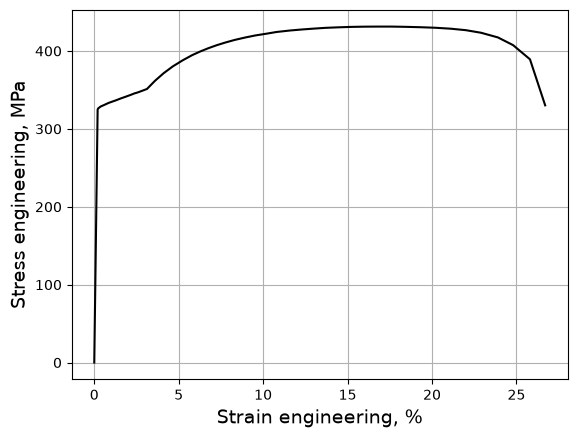

In [12]:
# визуализируем данные с помощью импортированной ранее библиотеки matplotlib

# создаем "базу" для графика
plt.plot (strain_eng, stress_eng, '-', color = 'black')
# Добавляем названия осей
plt.xlabel ('Strain engineering, %', fontsize = 14)
plt.ylabel ('Stress engineering, MPa', fontsize = 14)
# добавляем для красоты сетку
plt.grid()

In [13]:
# Расчет истинного напряжения и деформации
stress_true = [] # пустой список куда будем записывать значения истинного напряжения
strain_true = [] # пустой список куда будем записывать значения истинной деформации
for i in range (0, len(strain_eng)):
    stress_true.append(stress_eng[i]*(1+strain_eng[i]/100))
    strain_true.append(math.log(1+strain_eng[i]/100))

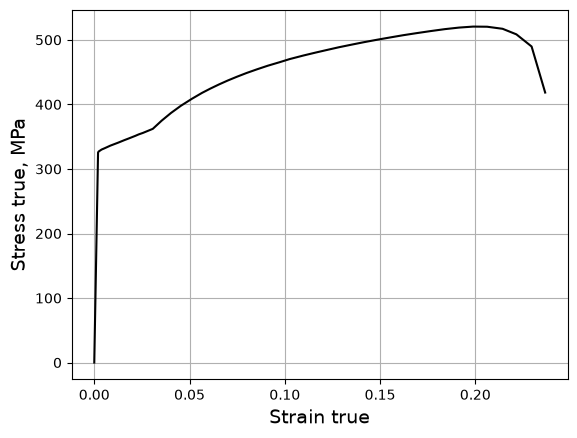

In [14]:
# создаем "базу" для графика
plt.plot (strain_true, stress_true, '-', color = 'black')
# Добавляем названия осей
plt.xlabel ('Strain true', fontsize = 14)
plt.ylabel ('Stress true, MPa', fontsize = 14)
# добавляем для красоты сетку
plt.grid()

In [15]:
tensile_stress = 0.0
for i in range (0, len(stress_eng)):
    if tensile_stress < stress_eng [i]:
        tensile_stress = stress_eng [i]
        its = i 
print (f'Rm = {tensile_stress} at the i ={its}')

Rm = 431.3 at the i =38


In [16]:
# Расчет равномерного удлинния
E = 210000 # модуль Юнга для стали принято брать 210 000 МПа
Ag = strain_eng[its] - (tensile_stress/E)*100
print (f'Elongation Ag = {round(Ag,3)}%')

Elongation Ag = 16.595%
